In [1]:
# Dependencies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer


In [2]:
# data

df = pd.read_csv('titanic_toy.csv')
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [3]:
df.shape

(891, 4)

In [4]:
# we have 891 rows

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [5]:
# as we can see some values are missing

df.isnull().sum()

Age         177
Fare         45
Family        0
Survived      0
dtype: int64

In [6]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [7]:
# so there is 19% missing --Age , and 5% missing in -- fare.   our role is to fill this data

In [8]:
# train test split

x = df.drop(columns=['Survived'])
y = df['Survived']


x_train,x_test,y_train,y_test = train_test_split(x , y ,
                                                test_size=0.2,
                                                random_state=2)

x_train.shape,x_test.shape

((712, 3), (179, 3))

In [9]:
x_train.isnull().mean()

Age       0.207865
Fare      0.050562
Family    0.000000
dtype: float64

## now we will replace missing with -- mean / median

In [10]:
x_train['Age'].mean()

29.78590425531915

In [11]:
mean_age = x_train['Age'].mean()
median_age = x_train['Age'].median()

mean_fare = x_train['Fare'].mean()
median_fare = x_train['Fare'].median()

In [12]:
median_age


28.75

In [13]:
mean_age

29.78590425531915

In [14]:
x_train['age_mean'] = x_train['Age'].fillna(mean_age)
x_train['age_median'] = x_train['Age'].fillna(median_age)

x_train['fare_mean'] = x_train['Fare'].fillna(mean_fare)
x_train['fare_median'] = x_train['Fare'].fillna(median_fare)

In [15]:
x_train.sample(5)

,Age,Fare,Family,age_mean,age_median,fare_mean,fare_median
203,45.5,7.225,0,45.500000,45.50,7.225,7.225
884,25.0,7.050,0,25.000000,25.00,7.050,7.050
482,50.0,8.050,0,50.000000,50.00,8.050,8.050
800,34.0,13.000,0,34.000000,34.00,13.000,13.000
26,NaN,7.225,0,29.785904,28.75,7.225,7.225


## after filling missing values -- always check variance 

## if it shrinks too much its a red flag 

In [16]:
print('Original Age variable variance: ', x_train['Age'].var())
print('Age Variance after median imputation: ', x_train['age_median'].var())
print('Age Variance after mean imputation: ', x_train['age_mean'].var())

print('Original Fare variable variance: ', x_train['Fare'].var())
print('Fare Variance after median imputation: ', x_train['fare_median'].var())
print('Fare Variance after mean imputation: ', x_train['fare_mean'].var())

Original Age variable variance:  204.3495133904614
Age Variance after median imputation:  161.98956633460543
Age Variance after mean imputation:  161.81262452718673
Original Fare variable variance:  2448.197913706318
Fare Variance after median imputation:  2340.0910219753637
Fare Variance after mean imputation:  2324.2385256705547


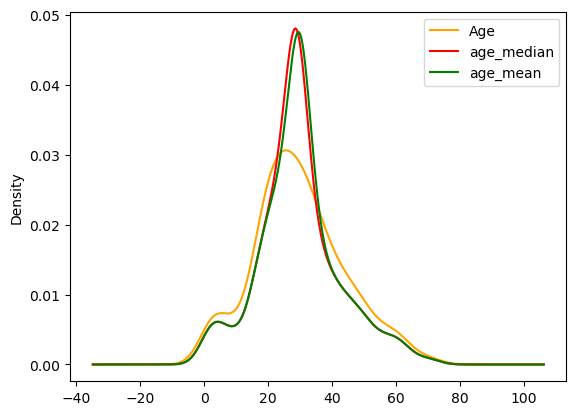

In [17]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
x_train['Age'].plot(kind='kde',color='orange' ,ax=ax)

# variable imputed with the median
x_train['age_median'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
x_train['age_mean'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [18]:
# as we can see the spike is too big , -- this is indicating red flag

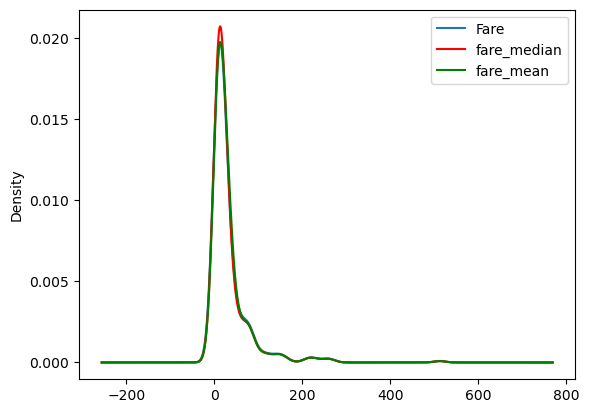

In [19]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
x_train['Fare'].plot(kind='kde', ax=ax)

# variable imputed with the median
x_train['fare_median'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
x_train['fare_mean'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [20]:
# this one is good since they almost over lap each other

In [21]:
# co-variance relation 

x_train.cov()

,Age,Fare,Family,age_mean,age_median,fare_mean,fare_median
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,66.665205,64.858859
Fare,70.719262,2448.197914,17.258917,55.603719,57.957599,2448.197914,2448.197914
Family,-6.498901,17.258917,2.735252,-5.146106,-5.112563,16.385048,16.476305
age_mean,204.349513,55.603719,-5.146106,161.812625,161.812625,52.788341,51.358000
age_median,204.349513,57.957599,-5.112563,161.812625,161.989566,55.023037,53.553455
fare_mean,66.665205,2448.197914,16.385048,52.788341,55.023037,2324.238526,2324.238526
fare_median,64.858859,2448.197914,16.476305,51.358000,53.553455,2324.238526,2340.091022


In [22]:
# co-relation

x_train.corr()

,Age,Fare,Family,age_mean,age_median,fare_mean,fare_median
Age,1.000000,0.092644,-0.299113,1.000000,1.000000,0.090156,0.087356
Fare,0.092644,1.000000,0.208268,0.088069,0.091757,1.000000,1.000000
Family,-0.299113,0.208268,1.000000,-0.244610,-0.242883,0.205499,0.205942
age_mean,1.000000,0.088069,-0.244610,1.000000,0.999454,0.086078,0.083461
age_median,1.000000,0.091757,-0.242883,0.999454,1.000000,0.089673,0.086982
fare_mean,0.090156,1.000000,0.205499,0.086078,0.089673,1.000000,0.996607
fare_median,0.087356,1.000000,0.205942,0.083461,0.086982,0.996607,1.000000


<Axes: >

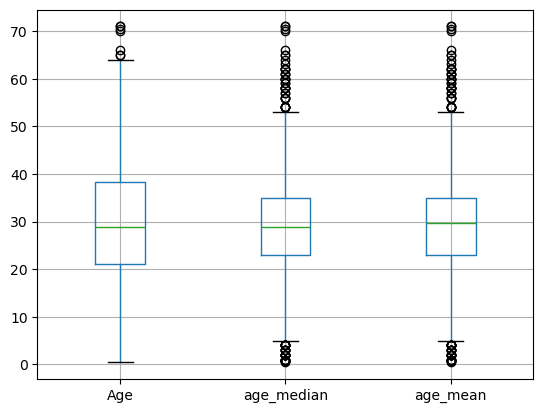

In [23]:
x_train[['Age', 'age_median', 'age_mean']].boxplot()

we can see after imputation --> this has introduced too much outliers in this data 
beacuse the IQR has shrinked in middle

<Axes: >

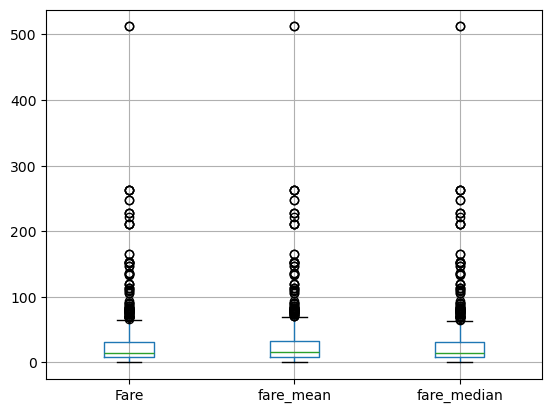

In [24]:
x_train[['Fare','fare_mean','fare_median']].boxplot()

In [25]:
# this is ok


# Doing the same thing using sklearn

In [26]:
mean_imputer = SimpleImputer(strategy='mean')
median_imputer = SimpleImputer(strategy='median')

In [27]:
x_train

,Age,Fare,Family,age_mean,age_median,fare_mean,fare_median
30,40.0,27.7208,0,40.000000,40.00,27.7208,27.7208
10,4.0,16.7000,2,4.000000,4.00,16.7000,16.7000
873,47.0,9.0000,0,47.000000,47.00,9.0000,9.0000
182,9.0,31.3875,6,9.000000,9.00,31.3875,31.3875
876,20.0,9.8458,0,20.000000,20.00,9.8458,9.8458
...,...,...,...,...,...,...,...
534,30.0,8.6625,0,30.000000,30.00,8.6625,8.6625
584,NaN,8.7125,0,29.785904,28.75,8.7125,8.7125
493,71.0,49.5042,0,71.000000,71.00,49.5042,49.5042
527,NaN,221.7792,0,29.785904,28.75,221.7792,221.7792


In [28]:
# transformer

trf = ColumnTransformer(transformers=[
    ('mean_imputer', mean_imputer, ['Age']),
    ('median_imputer', median_imputer, ['Fare'])
], remainder='passthrough')

In [29]:
# train test split

x = df.drop(columns=['Survived'])
y = df['Survived']


x_train,x_test,y_train,y_test = train_test_split(x , y ,
                                                test_size=0.2,
                                                random_state=2)

x_train.shape,x_test.shape

((712, 3), (179, 3))

In [30]:
x_train.head()

,Age,Fare,Family
30,40.0,27.7208,0
10,4.0,16.7000,2
873,47.0,9.0000,0
182,9.0,31.3875,6
876,20.0,9.8458,0


In [31]:
trf.fit(x_train)

ColumnTransformer(remainder='passthrough',
                  transformers=[('mean_imputer', SimpleImputer(), ['Age']),
                                ('median_imputer',
                                 SimpleImputer(strategy='median'), ['Fare'])])

In [32]:
trf.named_transformers_['mean_imputer'].statistics_

array([29.78590426])

In [33]:
trf.named_transformers_['median_imputer'].statistics_

array([14.4583])

In [34]:
# and as always == fit on train // transform both train and test

x_train = trf.transform(x_train)
x_test = trf.transform(x_test)

In [35]:
x_train

array([[ 40.        ,  27.7208    ,   0.        ],
       [  4.        ,  16.7       ,   2.        ],
       [ 47.        ,   9.        ,   0.        ],
       ...,
       [ 71.        ,  49.5042    ,   0.        ],
       [ 29.78590426, 221.7792    ,   0.        ],
       [ 29.78590426,  25.925     ,   0.        ]])